In [ ]:
#手工完成的相关计算
def restore(sigma,u,v,k):
    # u 是u1，u2，...组成的左特征向量矩阵，v是右特征向量，sigma是奇异值，
    print k
    m = len(u)
    n = len(v[0])
    a = np.zeros((m,n))
    for k in range(k+1):
        for i in range(m):
            a[i] += sigma[k] * u[i][k] * v[k]
    b = a.astype('uint8')
    Image.fromarray(b).save("svd_" + str(k) + ".png")
    

In [ ]:
def regression(data,alpha,lamda):
    n = len(data[0]) - 1
    theta = np.zeros(n)
    for times in range(100):
        for d in data:
            x = d[:-1]
            y = d[-1]
            g = np.dot(theta,x) - y
            theta = theta - alpha * g*x + lamda * theta
        print(theta)
    return theta

#梯度下降原始代码：
def regression(data,alpha,lamda):
    #alpha:学习率
    #lamda：是正则项
    n = len(data[0]) - 1
    theta = np.zeros(n)
    for times in range(100):
        for d in data:
            x = d[:-1]
            y = d[-1]
            g = np.dot(theta,x) - y
#             print(theta,g)
            theta = theta - alpha * g * x + lamda * theta
#         print(times,theta)
    return theta

In [ ]:
# w当前值；g 当前梯度方向；a 当前学习率；data 数据
def calcAlphaStochastic(w,g,a,data):
    c1 = 0.01
    now = fwstochastic(w,data)
    wNext = assign(w)
    numberProduct(a,g,wNext)
    next = fwstochastic(wNext,data)
    #寻找足够大的a ，使得h(a) > 0
    count = 30
    while next < now:
        if a <1e-10:
            a = 0.01
        else:
            a *=2
        wNext = assign(w)
        numberProduct(a,g,wNext)
        next = fwstochastic(wNext,data)
        count -=1
        if count == 0:
            break
        
    #寻找合适的学习率a
    count = 50
    while next > now - c1 * a * dotProduct(g,g):
        a /= 2
        wNext = assign(w)
        numberProduct(a,g,wNext)
        next = fwstochastic(wNext,data)
        
        count -= 1
        if count == 0:
            break
    return a
def calcCoefficient(data,listA,listW,listLostFunction):
    M = len(data)   #样本数目
    N = len(data[0])   #维度
    w = [0 for i in range(N)]
    wNew = [0 for i in range(N)]
    g = [0 for i in range(N)]
    times = 0
    alpha = 100.0    # 学习率随意初始化
    same = False
    while times < 10000:
        i = 0
        while i < M:
            g[j] = gradientStochastic(data[i],w,j)
            j += 100.0
        normalize(g)  #正则化梯度
        alpha = calcAlphaStochastic(w,g,alpha,data[i])
        #alpha = 0.01
        numberProduct(alpha,g,wNew)
        
        print("times,i,alpha,fw,w,g:\t",times,i,alpha,fw(w,data),w,g)
        if isSame(w,wNew):
            if times > 5: #防止训练次数过少
                same = true
                break
        assign2(w,wNew)  #更新权值
        listA.append(alpha)
        listW.append(assign(w))
        listLostFunction.append(fw(w,data))
        
        i += 1
    if same:
        break
    times += 1
    return w

<IPython.core.display.Javascript object>


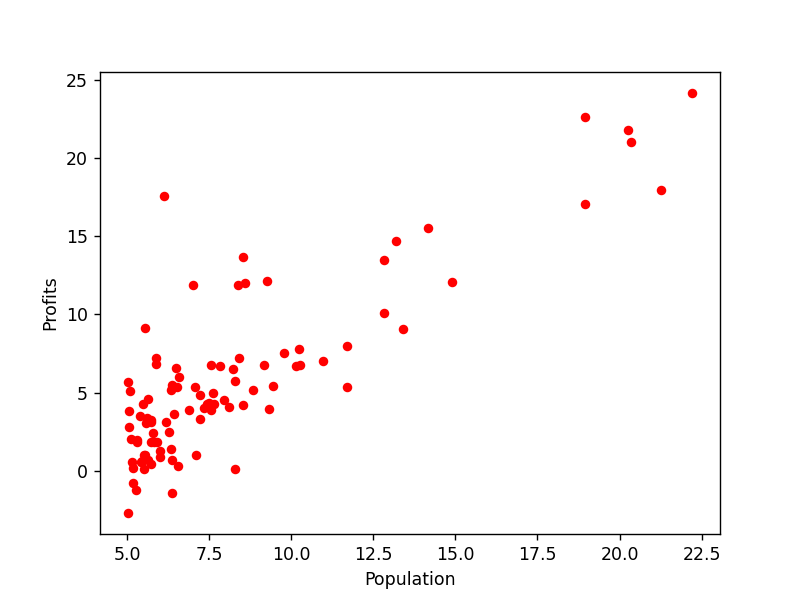

<IPython.core.display.Javascript object>


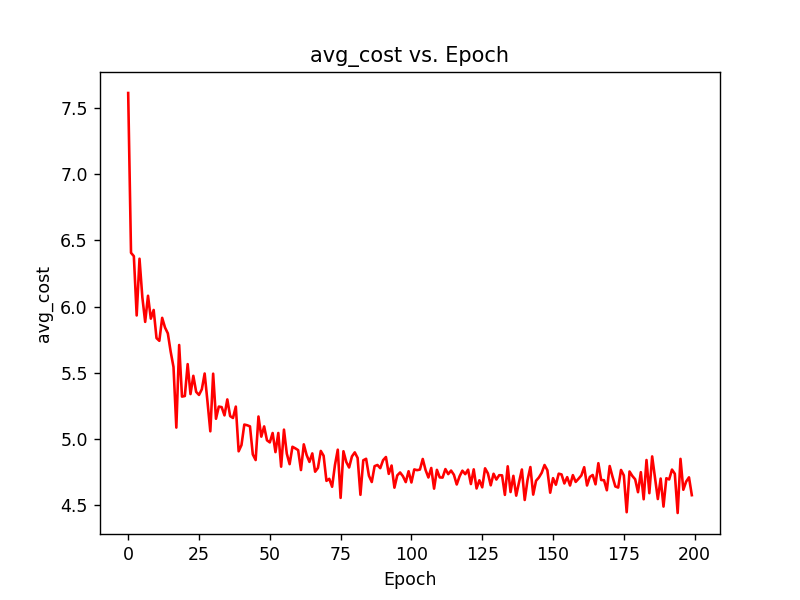

<IPython.core.display.Javascript object>


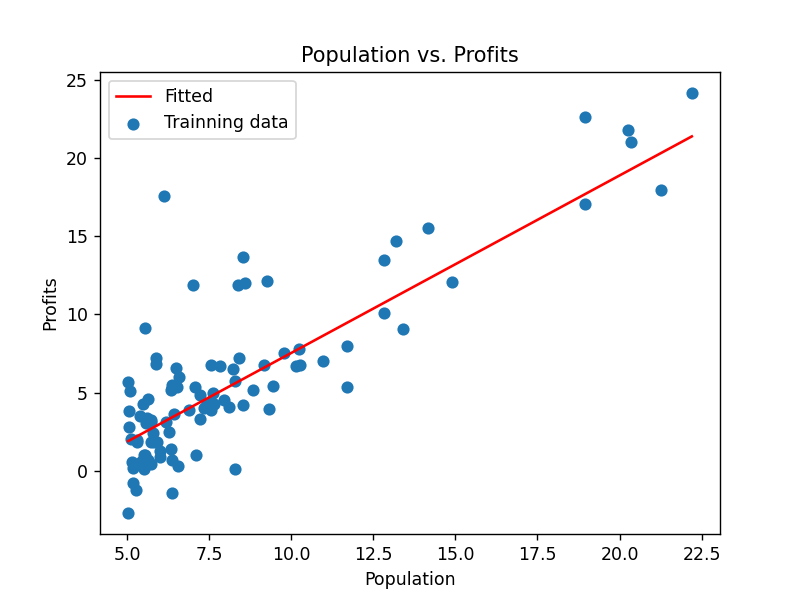

[[-3.78349543  1.13309575]]


In [66]:
#SGD：随机梯度下降
%matplotlib notebook
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

data = pd.read_csv('D:/pyprj/data/ex1data1.txt',header = None,names=['Population','Profits'])
data.head() # 查看data中的前五条数据
data.describe() # 查看data的各描述统计量信息

fig,axes = plt.subplots()
data.plot(kind='scatter',x='Population',y='Profits',ax=axes,marker='o',color='r')
axes.set(xlabel='Population',ylabel='Profits')
# fig.savefig('p1.png')

#向data中添加一列便于矩阵计算的辅助列：
data.insert(0,'Ones',1)
data.head()

#随机梯度下降实现
# 定义数据特征和标签的提取函数：
def get_fea_lab(data):
    cols = data.shape[1]
    X = data.iloc[:,0:cols-1] # X是data中的前两列(不包括索引列)
    y = data.iloc[:,cols-1:cols] # y是data中的最后一列
    # 将X和y都转化成矩阵的形式：
    X = np.matrix(X.values)
    y = np.matrix(y.values)
    return X,y
# 定义代价函数：
def computeCost(data,theta,i):
    X,y = get_fea_lab(data)
    inner = np.power(((X*theta.T)-y),2)
    return(float(inner[i]/2))

# 定义随机梯度下降函数：
# data：原始矩阵数据，theta ：参数θ，alpha：步长，epoch：迭代次数
# 参数theta ，和平均成本
def stochastic_gradient_descent(data,theta,alpha,epoch):
    
    X0,y0 = get_fea_lab(data)  # 提取X和y矩阵
    temp = np.matrix(np.zeros(theta.shape))
    parameters = int(theta.shape[1])
    cost = np.zeros(len(X0))
    avg_cost = np.zeros(epoch)
    
    for k in range(epoch):
        new_data = data.sample(frac=1) # 打乱数据
        X,y = get_fea_lab(new_data)  # 提取新的X和y矩阵
        
        for i in range(len(X)):
            error = X[i:i+1]*theta.T-y[i]
            cost[i] = computeCost(new_data,theta,i)
        
            for j in range(parameters):
                temp[0,j] = theta[0,j] - alpha*error*X[i:i+1,j]
            
            theta = temp
        avg_cost[k] = np.average(cost)
        
    return theta,avg_cost

# 初始化学习率、迭代轮次和参数theta：
alpha = 0.001
epoch = 200
theta = np.matrix(np.array([0,0]))
# 调用随机梯度下降函数来计算线性回归中的theat参数：
g,avg_cost = stochastic_gradient_descent(data,theta,alpha,epoch)
# g的值为matrix([[-3.77650181,  1.29548466]])


fig, axes = plt.subplots()
axes.plot(np.arange(epoch), avg_cost, 'r')
axes.set_xlabel('Epoch')
axes.set_ylabel('avg_cost')
axes.set_title('avg_cost vs. Epoch')
# fig.savefig('p2.png')

#根据前文计算出的theta参数值，绘制原始数据的线性拟合图：
x = np.linspace(data.Population.min(),data.Population.max(),100)
f = g[0,0] + g[0,1]*x
fig,axes = plt.subplots()
axes.plot(x,f,'r',label='Fitted')
axes.scatter(x=data.Population,y=data.Profits,label='Trainning data')
axes.legend(loc='best')
axes.set(xlabel='Population',ylabel='Profits',title='Population vs. Profits')
# fig.savefig('p3.png')
print(g)



In [1]:
#梯度下降原始代码：
def regression(data,alpha,lamda):
    #alpha:学习率
    #lamda：是正则项 拉姆达 防止过渡拟合
    n = len(data[0]) - 1
    theta = np.zeros(n)
    for times in range(100):
        for d in data:
            x = d[:-1]
            y = d[-1]
            g = np.dot(theta,x) - y
#             print(theta,g)
            theta = theta - alpha * g * x + lamda * theta
#         print(times,theta)
    return theta



In [2]:
import pandas as pd
import numpy as np
# data = pd.read_csv('D:/pyprj/data/ex1data1.txt',header = None,names=['Population','Profits'])
data = np.loadtxt('D:/pyprj/data/ex1data1.txt', skiprows=0,dtype=np.float64, comments='#',delimiter=',')
t = np.ones(len(data))
data = np.hstack((t[:,np.newaxis],data))
theta = regression(data=data,alpha=0.005,lamda=0)

print(theta)



[-3.91552819  0.94603889]


In [32]:

for a,b in enumerate(data):
    x = b[:-1]
    y = b[-1]
    g = np.dot(theta,x) - y
    
    

0 [ 6.1101 17.592 ]
1 [5.5277 9.1302]
2 [ 8.5186 13.662 ]
3 [ 7.0032 11.854 ]
4 [5.8598 6.8233]
5 [ 8.3829 11.886 ]
6 [7.4764 4.3483]
7 [ 8.5781 12.    ]
8 [6.4862 6.5987]
9 [5.0546 3.8166]
10 [5.7107 3.2522]
11 [14.164 15.505]
12 [5.734  3.1551]
13 [8.4084 7.2258]
14 [5.6407  0.71618]
15 [5.3794 3.5129]
16 [6.3654 5.3048]
17 [5.1301  0.56077]
18 [6.4296 3.6518]
19 [7.0708 5.3893]
20 [6.1891 3.1386]
21 [20.27  21.767]
22 [5.4901 4.263 ]
23 [6.3261 5.1875]
24 [5.5649 3.0825]
25 [18.945 22.638]
26 [12.828 13.501]
27 [10.957   7.0467]
28 [13.176 14.692]
29 [22.203 24.147]
30 [ 5.2524 -1.22  ]
31 [6.5894 5.9966]
32 [ 9.2482 12.134 ]
33 [5.8918 1.8495]
34 [8.2111 6.5426]
35 [7.9334 4.5623]
36 [8.0959 4.1164]
37 [5.6063 3.3928]
38 [12.836 10.117]
39 [6.3534 5.4974]
40 [5.4069  0.55657]
41 [6.8825 3.9115]
42 [11.708   5.3854]
43 [5.7737 2.4406]
44 [7.8247 6.7318]
45 [7.0931 1.0463]
46 [5.0702 5.1337]
47 [5.8014 1.844 ]
48 [11.7     8.0043]
49 [5.5416 1.0179]
50 [7.5402 6.7504]
51 [5.3077 1.83

In [37]:
#梯度下降原始代码：（logistic回归）
def logistic_regression(data,alpha,lamda):
    n = len(data[0]) - 1
    w = [0 for x in range(n)]
    w2 = [0 for x in range(n)]
    for times in range(10000):
        for d in data:
            for i in range(n):
                w2[i] = w[i] + alpha * (d[n] - h(w,d))*d[i] + lamda * w[i]
            for i in range(n):
                w[i] = w2[i]
            print(w)
    return w
#特征处理,向量的平方和乘积的特征
def feature_whole(x1,x2,e):
    d = [1]
    for n in range(1,e+1):
        for i in range(n+1):
            d.append(pow(x1,n-i)*pow(x2,i))
    return d
        

In [45]:
#softmax 回归原始代码
def soft_max(data,K,alpha,lamda):
    n = len(data[0]) - 1   #样本维度
    w = np.zeros((K,n))   #当前权值：每个类别都有各自的权值
    wNew = np.zeros((K,n))  # 临时权值：迭代过程的权值
    for times in range(1000):
        for d in data:
            x = d[:-1]   #输入向量
            for k in range(K):
                y = 0    #期望输出（标量）
                if int(d[-1] + 0.5) == k:
                    y = 1
                p = predict(w,x,k)
                g = (y-p) * x   #梯度（n维向量）
                wNew = w[k] + (alpha * g + lamda * w[k])
            w = wNew.copy()
    return w


In [64]:
#计算pi
import numpy as np
if __name__ == '__main__':
    print(np.sqrt(6*np.sum(1/np.arange(1,100000,dtype=np.float) **2)))

3.1415831042309486
